# 01 — Exploratory Data Analysis (FD001)

Goal of this notebook: get to know the **C-MAPSS FD001** subset before building any model.

Steps:
1. Load the train set, test set and true test RUL (loading code lives in `src/data.py`).
2. Compute the **Remaining Useful Life (RUL)** target for every row.
3. Find and drop sensors that are **constant** (they carry no information).
4. Plot how each remaining sensor **evolves as the engine approaches failure**.

FD001 is the simplest subset: **one operating condition** and **one fault mode** (HPC degradation), 100 training engines and 100 test engines.

## 0. Setup

The notebook lives in `notebooks/`, but our reusable code is in `src/`.
We add the project root (the parent folder) to Python's search path so that `from src.data import ...` works.

In [13]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Project root = parent of the "notebooks" folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import (
    SENSOR_COLUMNS,
    SETTING_COLUMNS,
    add_test_rul,
    add_train_rul,
    find_constant_columns,
    load_cmapss,
)

# Folder where we save the figures of this notebook
FIG_DIR = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the data

`load_cmapss("FD001")` reads three files from `data/raw/`:

| File | Content |
|---|---|
| `train_FD001.txt` | Full run-to-failure trajectories: each engine runs until it fails |
| `test_FD001.txt` | Trajectories cut off at some random point **before** failure |
| `RUL_FD001.txt` | True RUL of each test engine at its last recorded cycle |

Each row of train/test is **one engine at one cycle** with 26 columns:
engine id (`unit`), time (`cycle`), 3 operational settings and 21 sensor readings.
The raw files have no header, so the column names are defined in `src/data.py`.

In [14]:
train, test, test_rul = load_cmapss("FD001")

print("train:   ", train.shape)
print("test:    ", test.shape)
print("test_rul:", test_rul.shape)
train.head()

train:    (20631, 26)
test:     (13096, 26)
test_rul: (100, 2)


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Number of engines and how long they live. In the training set the last cycle of an engine is its failure cycle, so the maximum cycle per engine is its **lifetime**.

In [15]:
lifetimes = train.groupby("unit")["cycle"].max()

print("Train engines:", train["unit"].nunique())
print("Test engines: ", test["unit"].nunique())
print()
print("Lifetime of training engines (cycles):")
print(lifetimes.describe().round(1))

Train engines: 100
Test engines:  100

Lifetime of training engines (cycles):
count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


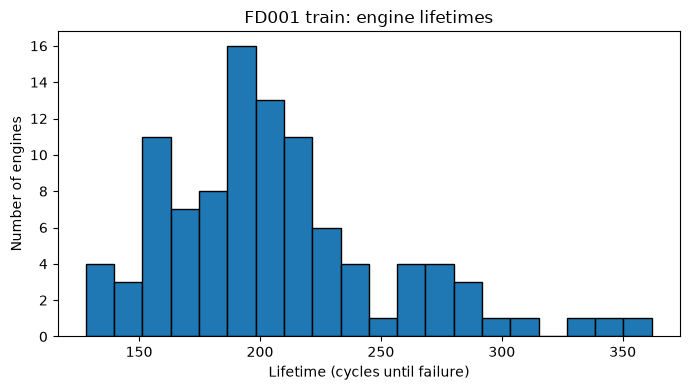

In [16]:
plt.figure(figsize=(7, 4))
plt.hist(lifetimes, bins=20, edgecolor="black")
plt.xlabel("Lifetime (cycles until failure)")
plt.ylabel("Number of engines")
plt.title("FD001 train: engine lifetimes")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_lifetimes_fd001.png", dpi=150)
plt.show()

Lifetimes vary a lot (roughly 130 to 360 cycles). This is why we cannot just predict "the average lifetime minus the current cycle": every engine starts with a different initial wear and degrades at its own speed. The sensors must tell us *how worn* the engine is.

## 2. Compute the RUL target

**RUL (Remaining Useful Life)** = number of cycles the engine still has before failure.

- **Train:** every engine runs until failure, so
  `RUL = last cycle of the engine − current cycle` (RUL = 0 at the failure cycle).
- **Test:** the trajectory stops before failure. `RUL_FD001.txt` gives the true RUL at the last recorded cycle, so
  `RUL = true_rul + last recorded cycle − current cycle`.

Both formulas are implemented in `add_train_rul` and `add_test_rul` in `src/data.py`.

*Note:* here we use the plain (linear) RUL. The **capped** RUL (max ≈ 125 cycles) will be introduced in the modelling notebooks.

In [17]:
train = add_train_rul(train)
test = add_test_rul(test, test_rul)

# Check on engine 1: RUL should go down by 1 each cycle and end at 0
train.loc[train["unit"] == 1, ["unit", "cycle", "RUL"]].tail()

,unit,cycle,RUL
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


In [18]:
# Check on the test set: the RUL at the last recorded cycle must equal the RUL file
last_test_rows = test.groupby("unit").tail(1)
same = (last_test_rows["RUL"].values == test_rul["true_rul"].values).all()
print("Test RUL at last cycle matches RUL_FD001.txt:", same)

Test RUL at last cycle matches RUL_FD001.txt: True


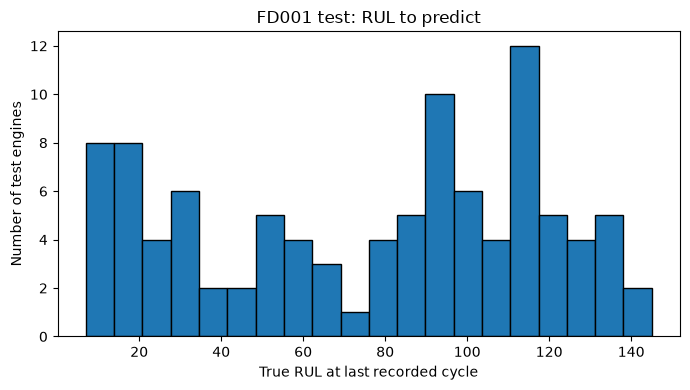

In [19]:
plt.figure(figsize=(7, 4))
plt.hist(test_rul["true_rul"], bins=20, edgecolor="black")
plt.xlabel("True RUL at last recorded cycle")
plt.ylabel("Number of test engines")
plt.title("FD001 test: RUL to predict")
plt.tight_layout()
plt.show()

The test engines are cut off at very different points: some have only a few cycles left, others more than 100. Our models will have to predict this RUL from the sensor history.

## 3. Drop constant sensors

A column that never changes cannot help to predict RUL. We check, for each operational setting and sensor, the **number of distinct values** and the **standard deviation**.

In [20]:
feature_columns = SETTING_COLUMNS + SENSOR_COLUMNS

variability = pd.DataFrame({
    "n_unique": train[feature_columns].nunique(),
    "std": train[feature_columns].std(),
})
variability

,n_unique,std
setting_1,158,2.187313e-03
setting_2,13,2.930621e-04
setting_3,1,0.000000e+00
sensor_1,1,0.000000e+00
sensor_2,310,5.000533e-01
sensor_3,3012,6.131150e+00
sensor_4,4051,9.000605e+00
sensor_5,1,5.329200e-15
sensor_6,2,1.388985e-03
sensor_7,513,8.850923e-01


Observations:
- `setting_3` and sensors **1, 5, 10, 16, 18, 19** take a **single value** → truly constant.
  This is expected: FD001 has only one operating condition.
- `sensor_6` takes only **2 values** (21.60 / 21.61), and almost all rows are 21.61. It is *quasi-constant*.
- `setting_1` and `setting_2` vary only by tiny amounts: they are just noise around one flight condition, not useful operating information in FD001.

In [21]:
constant_columns = find_constant_columns(train, feature_columns)
print("Constant columns:", constant_columns)

print()
print("sensor_6 value counts:")
print(train["sensor_6"].value_counts())

Constant columns: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

sensor_6 value counts:
sensor_6
21.61    20225
21.60      406
Name: count, dtype: int64


Decision for FD001:
- drop the constant columns found above;
- also drop `sensor_6` (quasi-constant, 98% of rows have the same value);
- also drop `setting_1` and `setting_2` (only noise, single operating condition).

This leaves **14 sensors**, which matches the selection commonly used in the C-MAPSS literature.

In [22]:
columns_to_drop = constant_columns + ["sensor_6", "setting_1", "setting_2"]

train = train.drop(columns=columns_to_drop)
test = test.drop(columns=columns_to_drop)

# The sensors we keep for the rest of the analysis
useful_sensors = [col for col in SENSOR_COLUMNS if col not in columns_to_drop]
print(len(useful_sensors), "sensors kept:", useful_sensors)

14 sensors kept: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 4. Sensor trends vs RUL

Now the key question: **do the sensors change as the engine approaches failure?**

For each kept sensor we plot its value against RUL:
- thin grey lines = 10 example engines (raw, noisy readings);
- red line = mean value over **all** training engines at each RUL.

The x-axis is **reversed** so that time flows from left to right and failure (RUL = 0) is on the right.

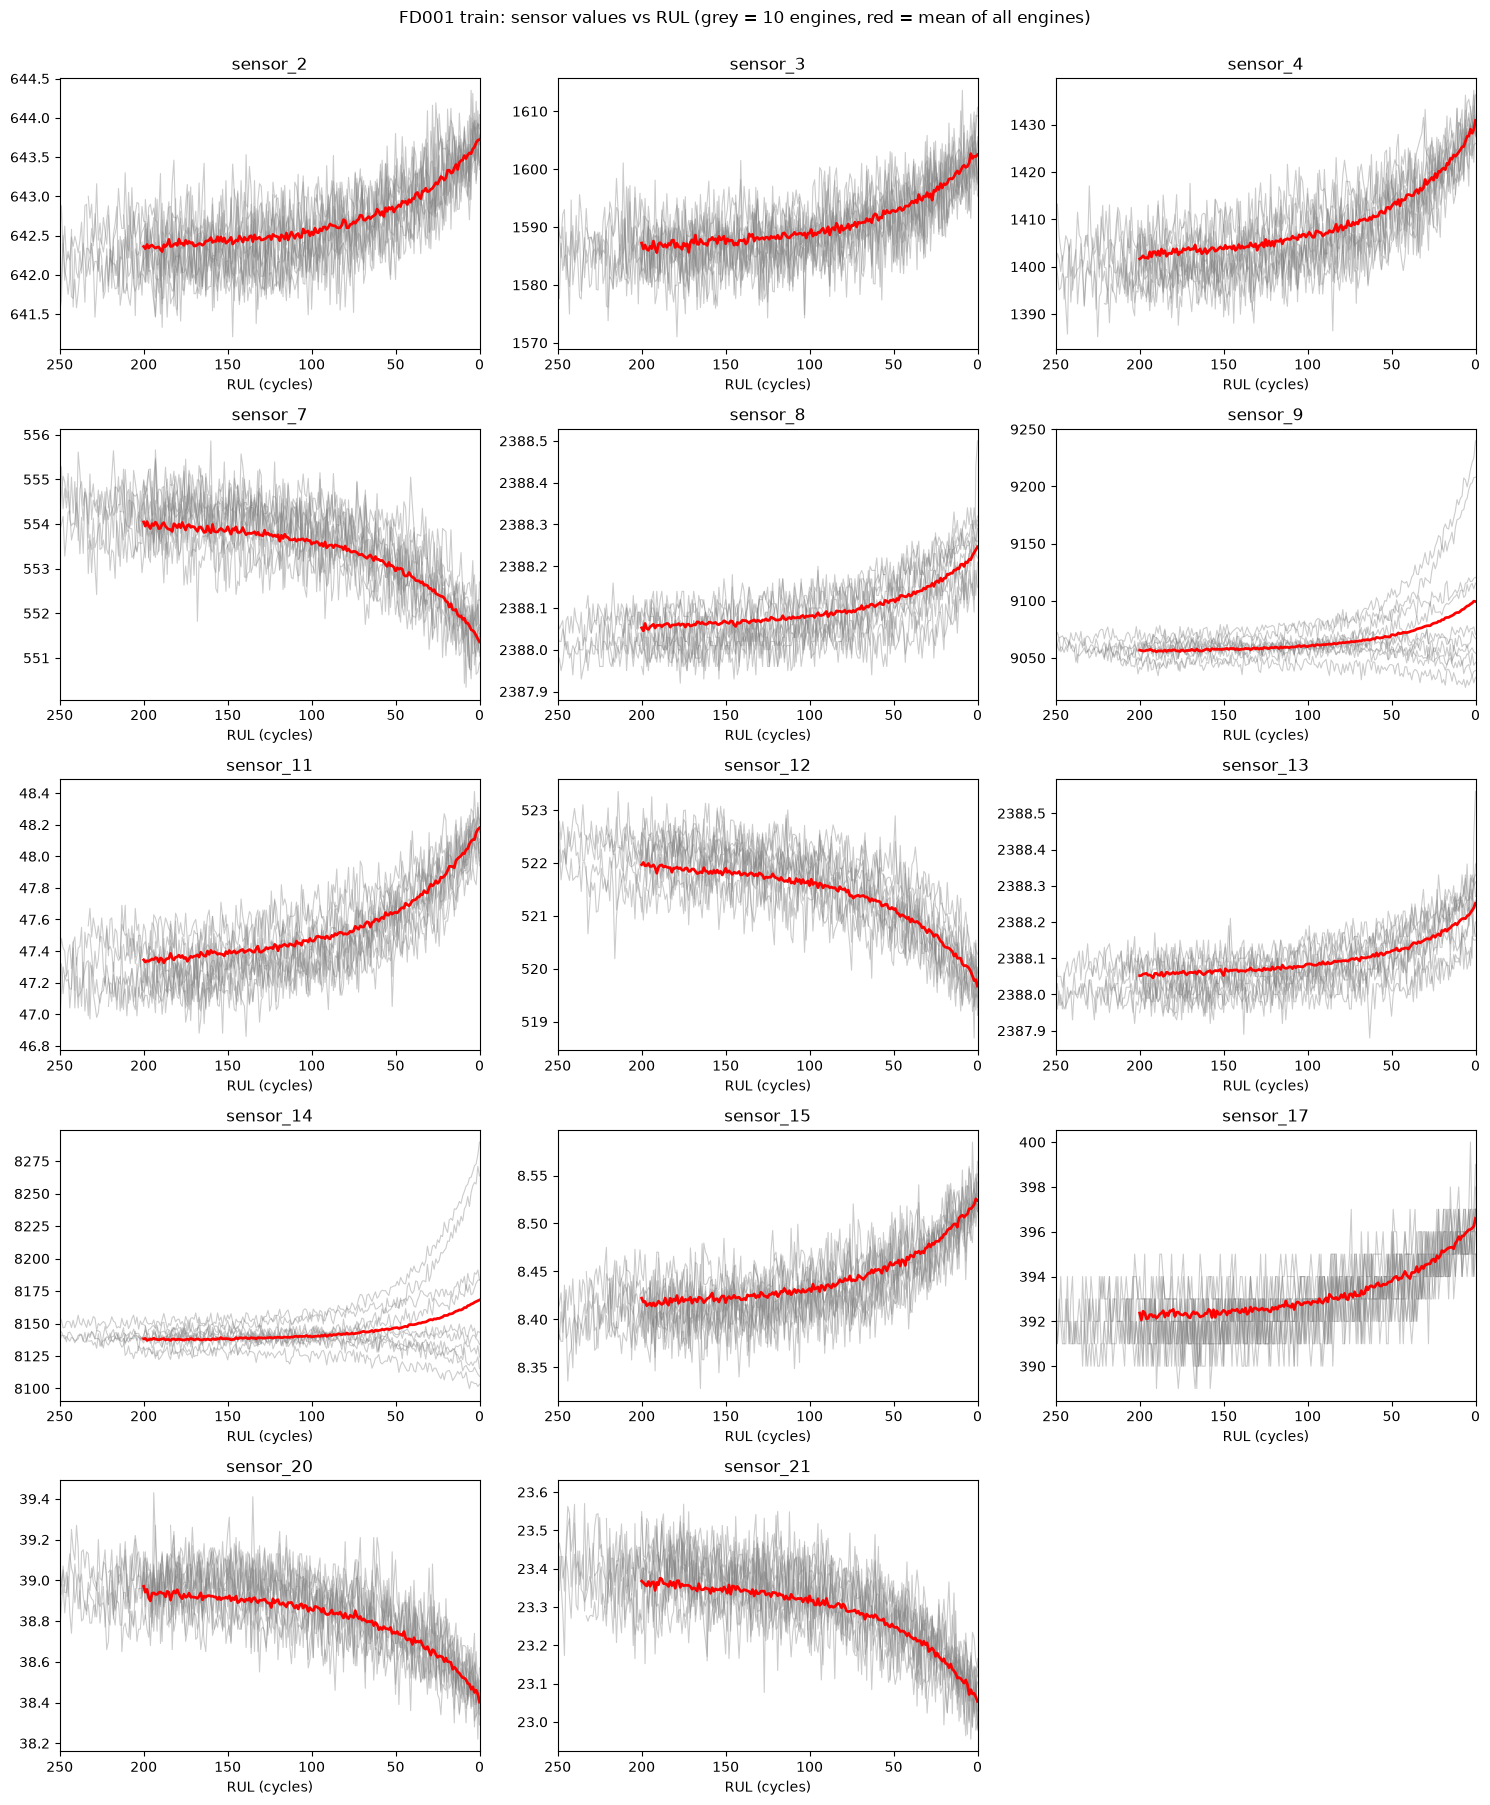

In [23]:
# Mean sensor value over all engines for each RUL value.
# We stop at RUL = 200 because only a few engines live longer,
# so the mean beyond that point is based on very few engines.
mean_by_rul = train[train["RUL"] <= 200].groupby("RUL")[useful_sensors].mean()

# 10 example engines chosen at random (fixed seed -> same plot every time)
rng = np.random.default_rng(42)
example_units = rng.choice(train["unit"].unique(), size=10, replace=False)

fig, axes = plt.subplots(5, 3, figsize=(15, 18))
axes = axes.flatten()

for i, sensor in enumerate(useful_sensors):
    ax = axes[i]
    # Raw trajectories of the example engines
    for unit in example_units:
        engine = train[train["unit"] == unit]
        ax.plot(engine["RUL"], engine[sensor], color="grey", alpha=0.4, linewidth=0.8)
    # Average trend over all engines
    ax.plot(mean_by_rul.index, mean_by_rul[sensor], color="red", linewidth=2)
    ax.set_title(sensor)
    ax.set_xlabel("RUL (cycles)")
    ax.set_xlim(250, 0)  # reversed: failure on the right

# We have 14 sensors and 15 subplots: hide the empty one
for j in range(len(useful_sensors), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("FD001 train: sensor values vs RUL (grey = 10 engines, red = mean of all engines)", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_sensor_trends_fd001.png", dpi=150)
plt.show()

What we see:
- Most sensors are **flat while the engine is healthy** (high RUL) and only start to drift in the last ~100–150 cycles. This is the reason behind **RUL capping** (≈125 cycles) used later: far from failure the sensors cannot distinguish RUL = 300 from RUL = 200.
- Some sensors **increase** towards failure (2, 3, 4, 8, 11, 13, 15, 17), others **decrease** (7, 12, 20, 21).
- Sensors 9 and 14 behave differently from engine to engine (some go up, some go down), so their average trend is weaker.
- Single readings are **noisy**: the trend is clear in the average but hard to see in one raw cycle. This motivates using **time windows** (several cycles at once) instead of a single row.

### Correlation with RUL

To summarise the plot with one number per sensor, we compute the **Pearson correlation** between each sensor and RUL (only rows with RUL ≤ 125, where degradation is visible).

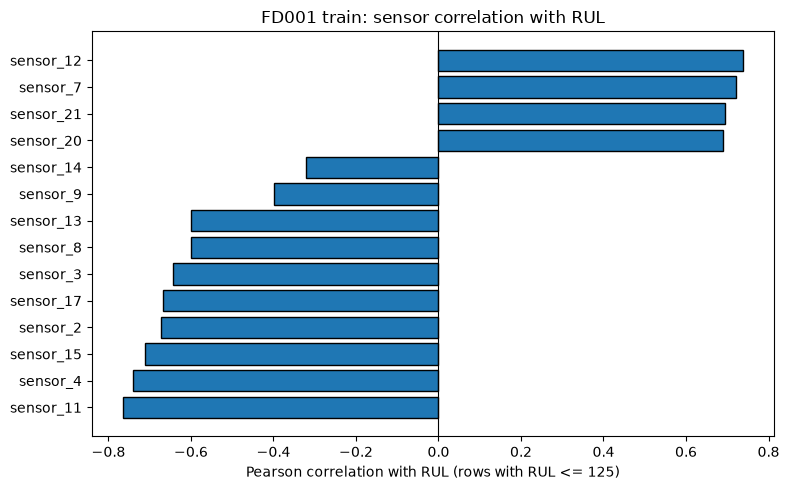

sensor_11   -0.77
sensor_4    -0.74
sensor_15   -0.71
sensor_2    -0.67
sensor_17   -0.67
sensor_3    -0.64
sensor_8    -0.60
sensor_13   -0.60
sensor_9    -0.40
sensor_14   -0.32
sensor_20    0.69
sensor_21    0.70
sensor_7     0.72
sensor_12    0.74
dtype: float64

In [25]:
near_failure = train[train["RUL"] <= 125]
correlation = near_failure[useful_sensors].corrwith(near_failure["RUL"]).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(correlation.index, correlation.values, edgecolor="black")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson correlation with RUL (rows with RUL <= 125)")
plt.title("FD001 train: sensor correlation with RUL")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_sensor_correlation_fd001.png", dpi=150)
plt.show()

correlation.round(2)

Negative correlation = the sensor **increases** as RUL goes down (towards failure); positive correlation = it **decreases**. Sensors 9 and 14 have the weakest correlation, consistent with the plot above.

## Summary

- FD001: 100 training engines (lifetimes ~130–360 cycles) and 100 test engines.
- RUL computed for train (`last cycle − cycle`) and test (using `RUL_FD001.txt`), checked against the RUL file.
- Dropped 7 constant columns, the quasi-constant `sensor_6` and the noise-only settings 1 and 2 → **14 sensors kept**.
- Sensors degrade mainly in the last ~125 cycles and are noisy → supports **RUL capping** and **time windows** in the next notebooks.